# QMSS5074GR: Projects in Advanced Machine Learning
## Project 1: World Happiness Classification

---

### Group Information

Fill this in before you submit.

**Group number:**

| Full Name | UNI |
|-----------|-----|
|Isha Malaviya           |im2650     |
|Siying Liu           |sl6073     |

**Public GitHub repository URL:**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## How to Complete and Submit This Project

**Due: Monday, October 19, 2026**

This notebook is the whole assignment. Everything you need to do is written here, and the completed notebook is the only thing you submit. Keep the file name `Project_1.ipynb`.

### 1. Get started

Everything you need comes in the project folder. No separate downloads are needed:

```
Fall2026_QMSS5074GR_Project_1/
├── Project_1.ipynb
└── data/
    ├── WHR_2023.csv
    └── newcountryvars.csv
```

1. Unzip the folder and open `Project_1.ipynb`.
2. Keep the `data` folder next to the notebook and don't rename any files. The code reads the data from `data/WHR_2023.csv` and `data/newcountryvars.csv`.
3. Run the first code cell in Section 0 to install the required packages.

### 2. Complete the notebook

- Every **`TODO`** marks something you must do: write code, choose parameters, or answer a question.
- Write your answers in the cells marked *Replace this section with your response.*
- Remove each `TODO` marker once you have completed it. Any `TODO` left at submission counts as **incomplete**.
- You may add extra cells for additional experiments.

### 3. Before you submit

- Run **Kernel → Restart & Run All**. The notebook must run from top to bottom without errors, with all outputs (tables, plots, scores) visible.
- Fill in the **Group Information** cell at the top, including your GitHub link.

### 4. Submit in two places

| Where | What to submit |
|-------|----------------|
| **Canvas** (Project 1 assignment) | This completed `.ipynb` file. **One member submits for the whole group.** |
| **GitHub** (your group's public repository) | The same `.ipynb`, inside a `Project_1` folder, with the `data` folder |

Your repository should look like this:

```
<your-group-repo>/
└── Project_1/
    ├── Project_1.ipynb
    └── data/
        ├── WHR_2023.csv
        └── newcountryvars.csv
```

The repository must be **public**. To check, open your link in a private/incognito browser window.

### Submission checklist

- [ ] Group number, names, UNIs, and GitHub link are filled in at the top
- [ ] No `TODO` is left anywhere in the notebook
- [ ] Restart & Run All finishes with no errors, and all outputs are visible
- [ ] One group member has submitted the `.ipynb` to Canvas
- [ ] The same `.ipynb` and the `data` folder are in `Project_1/` in your public group repository

## About the Project

### What this project is about

Why are people in some countries happier than in others? Every year, the **World Happiness Report** surveys people around the world (through the Gallup World Poll) and asks them to rate their current life on a ladder from **0 (worst possible life)** to **10 (best possible life)**. A country's happiness score is the average of these answers.

In this project, you will build models that **predict how happy a country is from its economic, social, and development indicators**, and then look inside those models to see which factors matter most. Along the way, you will practice the full machine learning workflow: merging datasets, exploring data, engineering features, building a preprocessing pipeline, training and tuning classical models, training a neural network, and explaining predictions with SHAP.

### The prediction task

This is a **multi-class classification** problem. In Section 0, the numeric `happiness_score` is split into **five equal-sized groups** (quintiles) of about 27 countries each:

**Very Low → Low → Average → High → Very High**

Your models predict which group each country belongs to. With only **137 countries** (95 for training, 42 for testing), this is a small dataset, so keep that in mind when you interpret your results.

---

### The data

You will work with two files, both in the `data` folder.

#### 1. `WHR_2023.csv`: World Happiness Report 2023 (137 countries)

| Column | What it means |
|--------|---------------|
| `country` | Country name (used to merge with the second file) |
| `region` | World region (10 regions, e.g., *Western Europe*, *Sub-Saharan Africa*) |
| `happiness_score` | Average life rating on the 0–10 ladder, from surveys in 2020–2022. **Used only to create the target, not as a feature.** |
| `gdp_per_capita` | Contribution of economic output per person |
| `social_support` | Contribution of having someone to count on in times of trouble |
| `healthy_life_expectancy` | Contribution of the number of years people live in good health |
| `freedom_to_make_life_choices` | Contribution of people's satisfaction with their freedom to choose what to do with their lives |
| `generosity` | Contribution of donating to charity (adjusted for income) |
| `perceptions_of_corruption` | Contribution of how widespread people think corruption is in government and business |

> **Important:** The six factor columns are **not** raw measurements. The World Happiness Report estimates how much each factor adds to a country's happiness score compared with *"Dystopia"*, an imaginary country with the world's lowest value of every factor. They are measured in **happiness-score points**. For example, Finland's `healthy_life_expectancy` is 0.535: health adds about half a point to Finland's score. It does *not* mean a life expectancy of 0.535 years.

#### 2. `newcountryvars.csv`: Country development indicators (174 countries)

| Column | What it means |
|--------|---------------|
| `country_name` | Country name (used to merge with the first file) |
| `population` | Total population |
| `population_below_poverty_line` | Percentage of people living below the national poverty line |
| `hdi` | Human Development Index (0–1): the UN's summary measure of health, education, and income |
| `life_expectancy` | Life expectancy at birth, in years |
| `expected_years_of_schooling` | Years of schooling a child starting school can expect to receive |
| `mean_years_of_schooling` | Average years of schooling completed by adults aged 25 and older |
| `gni` | Gross National Income per person, in international dollars adjusted for cost of living (PPP) |

These indicators come from roughly **2015–2017**, a few years earlier than the happiness surveys, and some values are missing.

#### Combining the two files

In Section 0, you will merge the second file into the first using `country` and `country_name`. Not every country appears in both files, and some countries are spelled differently, so check the merge carefully.

---

## 0. Loading Datasets

In this section, we load the two datasets described above, `WHR_2023.csv` and `newcountryvars.csv`, create the target variable, split the data into training and test sets, and merge in the extra country indicators.

**Objectives of this stage:**

- Import the datasets into the notebook environment
- Inspect their structure and contents
- Verify column names and data types
- Identify potential inconsistencies before merging

> Careful dataset inspection at this stage prevents downstream errors and ensures a clean modeling pipeline.

In [2]:
# Install the packages used in this project (quick if they are already installed)
%pip install -q pandas numpy scikit-learn matplotlib tensorflow shap

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the dataset
whr_df = pd.read_csv('/content/drive/MyDrive/Fall2026_QMSS5074GR_Project_1/data/WHR_2023.csv')

# Inspect the first few rows to understand the structure
whr_df


,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption
0,Finland,Western Europe,7.804,1.888,1.585,0.535,0.772,0.126,0.535
1,Denmark,Western Europe,7.586,1.949,1.548,0.537,0.734,0.208,0.525
2,Iceland,Western Europe,7.530,1.926,1.620,0.559,0.738,0.250,0.187
3,Israel,Middle East and North Africa,7.473,1.833,1.521,0.577,0.569,0.124,0.158
4,Netherlands,Western Europe,7.403,1.942,1.488,0.545,0.672,0.251,0.394
...,...,...,...,...,...,...,...,...,...
132,Congo (Kinshasa),Sub-Saharan Africa,3.207,0.531,0.784,0.105,0.375,0.183,0.068
133,Zimbabwe,Sub-Saharan Africa,3.204,0.758,0.881,0.069,0.363,0.112,0.117
134,Sierra Leone,Sub-Saharan Africa,3.138,0.670,0.540,0.092,0.371,0.193,0.051
135,Lebanon,Middle East and North Africa,2.392,1.417,0.476,0.398,0.123,0.061,0.027


In [4]:
# Convert the regression target ('happiness_score') into classification labels
# We'll use quintiles to create 5 happiness categories: Very Low, Low, Average, High, Very High

# Define quintiles
whr_df['happiness_category'] = pd.qcut(whr_df['happiness_score'],
                                       q=5,
                                       labels=['Very Low', 'Low','Average', 'High', 'Very High'])

# Select features and target
X = whr_df.drop(columns=['happiness_score', 'happiness_category'])
y = whr_df['happiness_category']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Convert y_train and y_test to numerical labels
y_train_labels = y_train.astype('category').cat.codes
y_test_labels = y_test.astype('category').cat.codes

### Conceptual Question

In the next cell, briefly explain the following:

1. What does `y_train.astype('category').cat.codes` do?
2. What is the difference between `y_train_labels` and `y_train`?

Keep your explanation clear and concise.

1. y_train.astype('category').cat.codes converts the 5 hapiness categories from text into numerical codes.
2. y_train_labels holds the y_train column of hapiness categories in numerical form and y_train holds the originally defined quintiles with categorical text labels.

### Add New Data

In [5]:
# Country development indicators to merge
countrydata=pd.read_csv("/content/drive/MyDrive/Fall2026_QMSS5074GR_Project_1/data/newcountryvars.csv")

countrydata.head()

,country_name,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,India,1339180127,21.9,0.623559,68.322,11.696590,6.298834,5663.474799
1,Nigeria,190886311,70.0,0.527105,53.057,9.970482,6.000000,5442.901264
2,Mexico,129163276,46.2,0.761683,76.972,13.299090,8.554985,16383.106680
3,Pakistan,197015955,29.5,0.550354,66.365,8.106910,5.089460,5031.173074
4,Bangladesh,164669751,31.5,0.578824,71.985,10.178706,5.241577,3341.490722


In [6]:
# Merge in new data to X_train and X_test by taking "country" from first table and "country_name" from 2nd table.
# Also check which countries are common in both the datasets, and which type of merge will you perform for the best results.
# Hint: Look at the 'how' parameter of the pandas merge function.
# Note: Your merge must keep every row of X_train and X_test so they stay aligned with y_train and y_test.
# Some country names differ between the two files; you may optionally harmonize them before merging.
fixed_labels={"Congo (Kinshasa)":"Democratic Republic of the Congo","VietNam":"Vietnam","Hong Kong S.A.R. of China":"Hong Kong","State of Palestine":"Palestine","Turkey":"Turkiye","Macedonia":"North Macedonia","Congo (Brazzaville)":"Congo","Czechia":"Czech Republic"}
countrydata["country_name"] = countrydata["country_name"].replace(fixed_labels)
countrydata.rename(columns={"country_name":"country"},inplace=True)
X_train["country"] = X_train["country"].replace(fixed_labels)
X_test["country"] = X_test["country"].replace(fixed_labels)
X_train = pd.merge(X_train, countrydata, on="country", how="left")
X_test = pd.merge(X_test, countrydata, on="country",how="left")


In [7]:
X_train.head(5)

,country,region,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,Madagascar,Sub-Saharan Africa,0.632,0.779,0.178,0.187,0.177,0.134,25570895.0,70.7,0.512149,65.515,10.34614,6.145955,1319.699397
1,Mauritania,Sub-Saharan Africa,1.099,0.764,0.244,0.320,0.130,0.195,4420184.0,31.0,0.513106,63.239,8.46379,4.266000,3527.264154
2,Mongolia,East Asia,1.379,1.494,0.244,0.425,0.239,0.058,3075647.0,21.6,0.734832,69.806,14.84552,9.750000,10449.207270
3,Tajikistan,Commonwealth of Independent States,0.972,1.248,0.291,0.599,0.104,0.292,8921343.0,31.5,0.627472,69.582,11.26186,10.355820,2600.585607
4,Ukraine,Central and Eastern Europe,1.358,1.354,0.355,0.551,0.265,0.016,44222947.0,24.1,0.743049,71.129,15.30672,11.340000,7361.011228


In [10]:
X_train.index = y_train.index
X_test.index = y_test.index
countries = set(X["country"].replace(fixed_labels))
extra_countries = set(countrydata["country"])

print("Common countries:", sorted(countries & extra_countries))
print("Unmatched countries:", sorted(countries - extra_countries))

for name, merged, target in [
    ("Training", X_train, y_train),
    ("Test", X_test, y_test)
]:
    original = X.loc[target.index].copy()
    original["country"] = original["country"].replace(fixed_labels)

    expected = original.merge(
        countrydata,
        on="country",
        how="left",
        sort=False,
        validate="many_to_one"
    )

    actual = merged.reset_index(drop=True)
    expected = expected.reset_index(drop=True)

    print(f"\n{name}:")
    print("Rows preserved:", len(actual) == len(original))
    print("Correct country and target order:",
          actual["country"].tolist() == original["country"].tolist())

    try:
        pd.testing.assert_frame_equal(
            actual, expected, check_dtype=False, check_exact=True
        )
        print("All merged values correct: True")
    except AssertionError as error:
        print("All merged values correct: False")
        print(error)

    print("Index labels match:", merged.index.equals(target.index))

Common countries: ['Afghanistan', 'Albania', 'Algeria', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Bahrain', 'Bangladesh', 'Belgium', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Cambodia', 'Cameroon', 'Canada', 'Chad', 'Chile', 'China', 'Colombia', 'Comoros', 'Congo', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Democratic Republic of the Congo', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Finland', 'France', 'Gabon', 'Gambia', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Honduras', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Ivory Coast', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyzstan', 'Laos', 'Latvia', 'Lebanon', 'Liberia', 'Lithuania', 'Luxembourg', 'Madagascar', 'Malawi', 'Malaysia', 'Mali', 'Malta', 'Mauritania', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', '

---

## 1. Exploratory Data Analysis and Visualization (EDAV)

In [11]:
print(X_train.dtypes)

country                           object
region                            object
gdp_per_capita                   float64
social_support                   float64
healthy_life_expectancy          float64
freedom_to_make_life_choices     float64
generosity                       float64
perceptions_of_corruption        float64
population                       float64
population_below_poverty_line    float64
hdi                              float64
life_expectancy                  float64
expected_years_of_schooling      float64
mean_years_of_schooling          float64
gni                              float64
dtype: object


### Describe What You Observe

Other than country and region, which remain as categorical labels, all the variables contained in the training set are all numerical (float types).

### Missing Values Analysis

Compute the number and percentage of missing values for each column and present the results in a clear summary table.

In [12]:
na_num =X_train.isna().sum()
na_percent = X_train.isna().mean()*100
missing_vals=pd.DataFrame({"NA Count":(na_num),"NA Percentage (%)":na_percent})
missing_vals

,NA Count,NA Percentage (%)
country,0,0.000000
region,0,0.000000
gdp_per_capita,0,0.000000
social_support,0,0.000000
healthy_life_expectancy,0,0.000000
freedom_to_make_life_choices,0,0.000000
generosity,0,0.000000
perceptions_of_corruption,0,0.000000
population,1,1.052632
population_below_poverty_line,11,11.578947


### Distribution of Key Numerical Features

Select relevant numerical features and plot their histograms. Choose features that may influence the target variable, and briefly comment on notable patterns, skewness, or outliers.

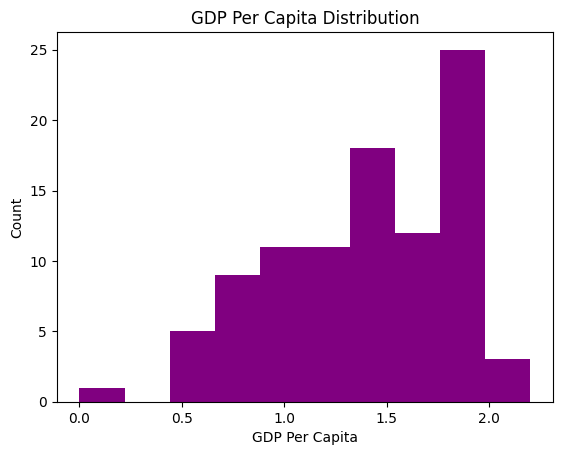

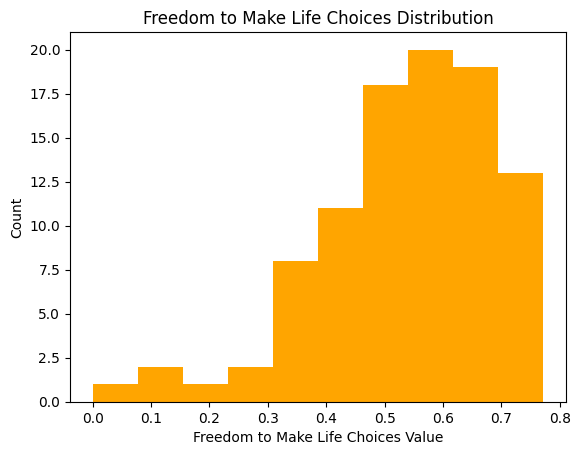

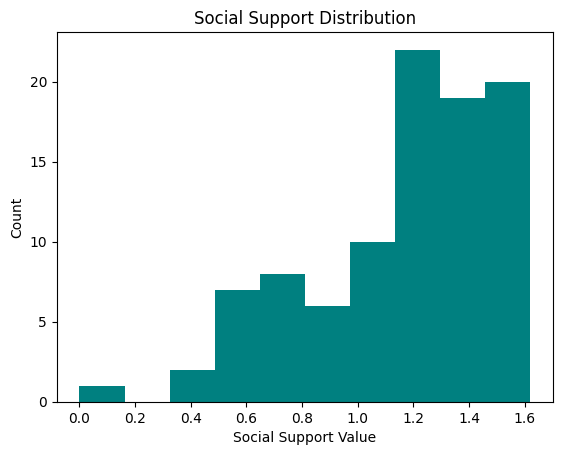

In [13]:
import matplotlib.pyplot as plt
plt.hist(X_train["gdp_per_capita"],color="purple")
plt.xlabel("GDP Per Capita")
plt.ylabel("Count")
plt.title("GDP Per Capita Distribution")
plt.show()
plt.hist(X_train["freedom_to_make_life_choices"],color="orange")
plt.xlabel("Freedom to Make Life Choices Value")
plt.ylabel("Count")
plt.title("Freedom to Make Life Choices Distribution")
plt.show()
plt.hist(X_train["social_support"],color="teal")
plt.xlabel("Social Support Value")
plt.ylabel("Count")
plt.title("Social Support Distribution")
plt.show()

GDP per capita's distribution has a moderate left skew, with a higher peak in the 1.8-2.0 range and another at 1.4, suggesting a split between higher-income and middle-income countries. There is one outlier near 0.0-0.2 and only ~3 countries past 2.0.

Freedom to make life choices has a strongly left-skewed distribution with a peak between 0.55-0.65, suggesting high perceived individual liberties in the majority of sampled countries. There are no isolated outliers but ~4 nations score below 0.3.

The social support distribution is also strongly left-skewed. The distribution peaks between 1.2 and 1.3 and a majority of countries score above 1.2. There is a single outlier in the 0.0-0.2 range.

All three distributions are skewed left. As the sample contains 95 countries with a diverse range of GDP values, these visualizations suggest that the skews in the data are more likely to represent the current state of global development rather than sampling bias. The data shows a pattern of inequality between the majority of the sample, experiencing moderate to high development, and the thin left tails showing the minority of countries in the sample that are less developed (based on their values for these 3 metrics).

### Distribution of Categorical Variables

Plot the distribution of relevant categorical variables using appropriate visualizations (e.g., count plots or bar charts). Briefly comment on class imbalance or notable patterns.

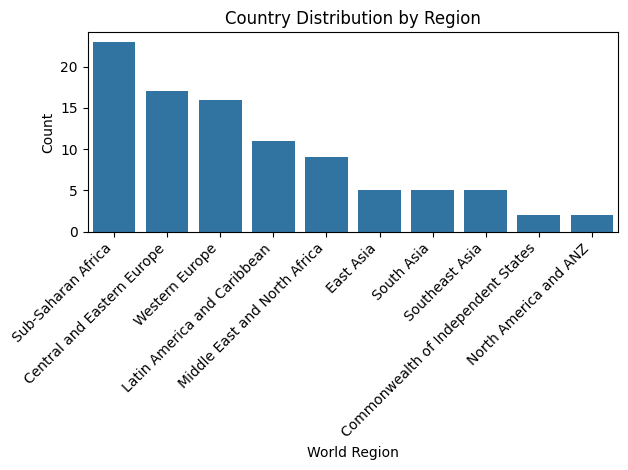

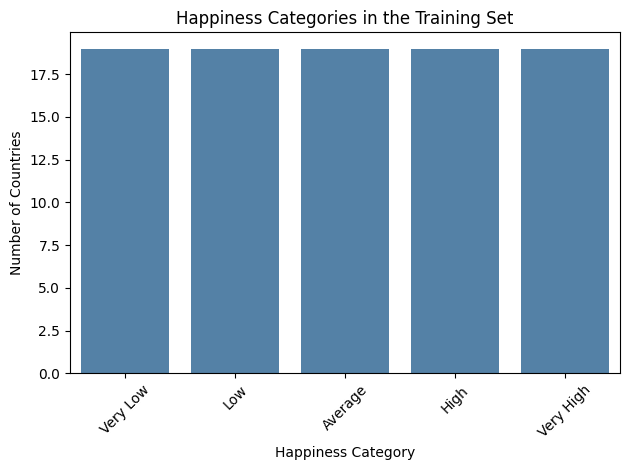

In [19]:
import seaborn as sns
sns.countplot(x="region", data=X_train, order=X_train['region'].value_counts().index)
plt.xlabel("World Region")
plt.ylabel("Count")
plt.title("Country Distribution by Region")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

category_order = ["Very Low", "Low", "Average", "High", "Very High"]
sns.countplot(
    x=y_train,
    order=category_order,
    color="steelblue"
)
plt.xlabel("Happiness Category")
plt.ylabel("Number of Countries")
plt.title("Happiness Categories in the Training Set")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Countries in Africa and Europe are highly represented in the sample, accounting for over half of the 95 countries. After them, Latin America and the Caribbean is the most represented. East, Southeast, and South Asia have a uniform distribution of 5 countries each.  Nations from North America and the Commonwealth of Independent States (post-Soviet states) are underrepresented, with ~2 countries from each region. Overall this demonstrates a strong class imbalance that could influence the external validity of our findings.

The five happiness categories are evenly balanced, with 19 countries in each category.

### Feature Correlation Analysis

Analyze the relationships between numerical features using correlation coefficients. Compute and visualize:

- **Pearson correlation** — linear relationships
- **Spearman correlation** — monotonic relationships
- **Kendall correlation** — rank-based relationships

Use correlation matrices and heatmaps where appropriate. Briefly interpret strong positive or negative correlations and discuss potential multicollinearity.

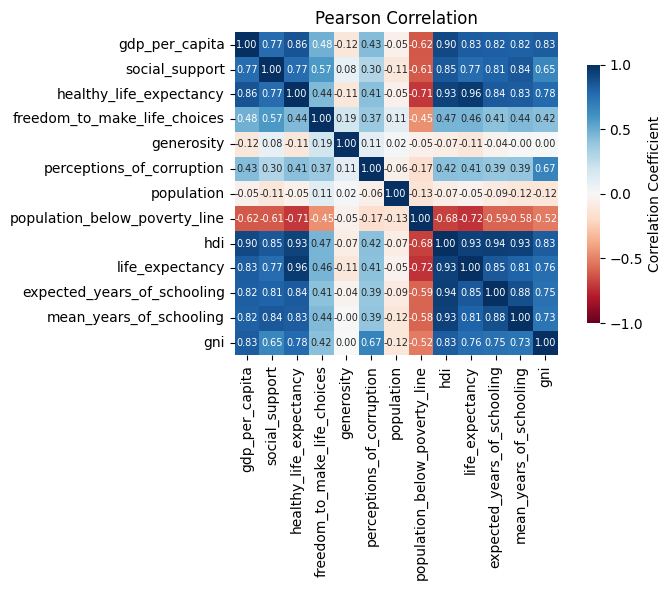

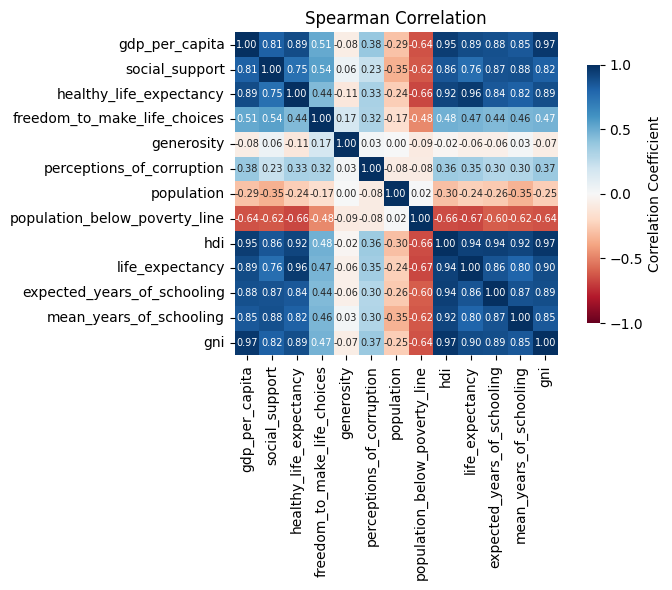

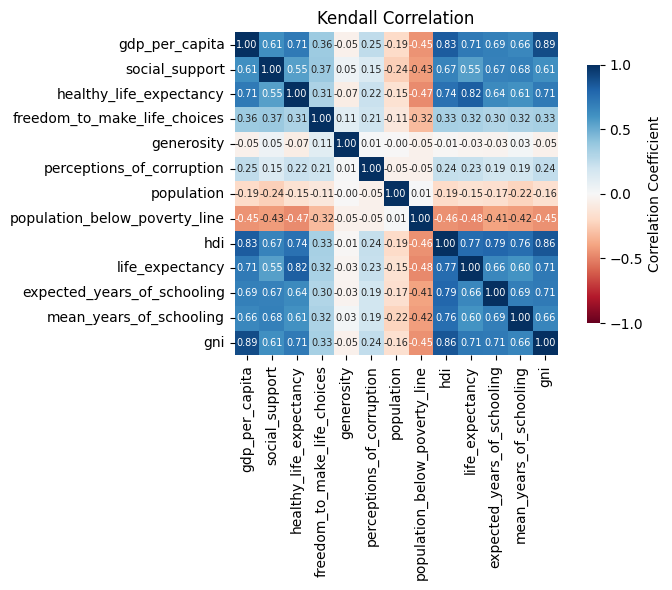

In [15]:
X_train_num = X_train.select_dtypes(include=['float64'])
heatmap_kwargs = {"cmap": "RdBu","vmin": -1,"vmax": 1,"annot": True, "fmt": ".2f", "annot_kws": {"size": 7}, "square": True,
"cbar_kws": {"label": "Correlation Coefficient", "shrink": 0.8,"ticks": [-1, -0.5, 0, 0.5, 1],},}

plt.figure(figsize=(8, 6))
sns.heatmap(X_train_num.corr(method="pearson"),cbar=True,**heatmap_kwargs)
plt.title("Pearson Correlation")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 6))
sns.heatmap(X_train_num.corr(method="spearman"),cbar=True,**heatmap_kwargs)
plt.title("Spearman Correlation")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 6))
sns.heatmap(X_train_num.corr(method="kendall"),cbar=True,**heatmap_kwargs)
plt.title("Kendall Correlation")
plt.tight_layout()
plt.show()


Across the correlation types, the correlations between the human development index (HDI) and expected years of schooling, HDI and GDP per capita, HDI and gross national income per person (GNI), HDI and healthy life expectancy, and GDP per capita and GNI are strong and positive. This demonstrates that countries with higher economic indicators tend to have higher health and education indicators. In all three matrices, the population below the poverty line shows a moderate to strong negative correlation with HDI, life expectancy/healthy life expectancy, and expected/mean years of schooling. This demonstrates that the poverty level of a country's population is strongly negatively associated with positive societal markers.

The strong correlations suggest potential multicollinearity. Variables like life expectancy and healthy life expectancy, and expected years of schooling and mean years of schooling have strong positive correlations with each other because they measure related aspects of health and education. GDP per capita, HDI, and GNI also show very high Pearson and Spearman correlations, suggesting they contain overlapping information (since HDI combines income, education, and health indicators, while GDP per capita and GNI per person are related economic measures).

### Bivariate Analysis and Relationship Exploration

Explore relationships between features and examine how they associate with the target variable. Include:

- Bivariate plots (e.g., scatter plots, box plots, grouped bar charts)
- Correlation tables
- Comparisons of feature distributions across target classes

Briefly summarize key relationships and any patterns that may influence model performance.

,0
gdp_per_capita,0.841157
social_support,0.836026
hdi,0.828013
gni,0.824569
mean_years_of_schooling,0.785350
expected_years_of_schooling,0.780972
life_expectancy,0.773022
healthy_life_expectancy,0.756918
freedom_to_make_life_choices,0.613986
perceptions_of_corruption,0.361975


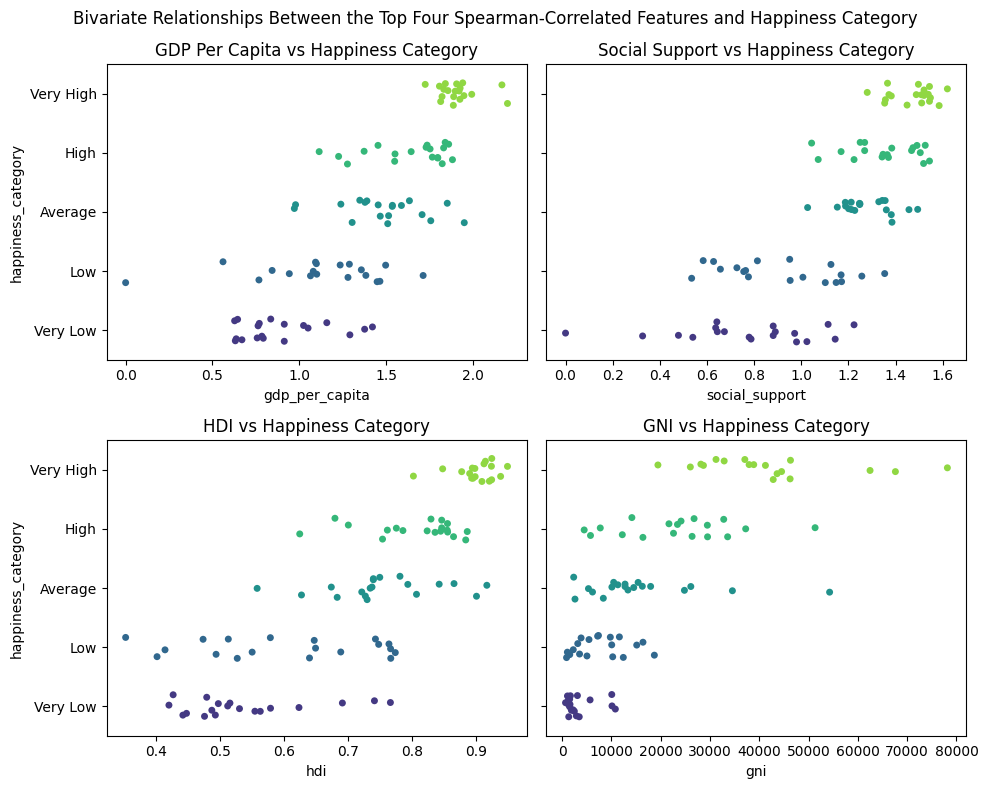

In [21]:
display((X_train_num.corrwith(y_train_labels, method='spearman')).sort_values(ascending=False))

cat_order =["Very High","High","Average","Low","Very Low"]
fig, axes = plt.subplots(2, 2,figsize=(10, 8),sharey=True)

sns.stripplot(x=X_train_num['gdp_per_capita'], y=y_train, order=cat_order, hue=y_train, legend=False, palette="viridis", jitter=0.2, ax=axes[0, 0])
axes[0, 0].set_title('GDP Per Capita vs Happiness Category')
sns.stripplot(x=X_train_num['social_support'], y=y_train, order=cat_order, hue=y_train, legend=False, palette="viridis", jitter=0.2, ax=axes[0, 1])
axes[0, 1].set_title('Social Support vs Happiness Category')
sns.stripplot(x=X_train_num['hdi'], y=y_train, order=cat_order, hue=y_train, legend=False, palette="viridis", jitter=0.2, ax=axes[1, 0])
axes[1, 0].set_title('HDI vs Happiness Category')
sns.stripplot(x=X_train_num['gni'], y=y_train, order=cat_order, hue=y_train, legend=False, palette="viridis", jitter=0.2, ax=axes[1, 1])
axes[1, 1].set_title('GNI vs Happiness Category')
fig.suptitle("Bivariate Relationships Between the Top Four Spearman-Correlated Features and Happiness Category")
plt.tight_layout()
plt.show()

To compare the happiness category to the numerical features, we used the Spearman correlation, which works best for measuring the relationship between an ordinal and continous variable.

The top four correlation coefficients are strongly positive, indicating strong monotonic relationships between these features and the happiness category. GDP per capita has the strongest correlation of 0.841157, the second highest one is social support with a correlation of 0.836026, the third one is HDI with a correlation of 0.828013, and the last one is GNI with a correlation of 0.824569.

The plots show that countries in higher happiness categories tend to have higher GDP per capita and social support contributions, HDI, and GNI. However, there is variation within happiness categories and overlap between categories. For example, some countries in the Average and High happiness categories have similar HDI values. GNI also shows a wide spread within the Very High happiness category, with a few countries having particularly high values. With the strong positive correlations, these patterns suggest that the four features may help distinguish between happiness categories.

### Outlier Detection

Identify potential outliers in the numerical features using appropriate methods such as:

- Box plots
- Z-score analysis
- Interquartile Range (IQR) method

Highlight any significant anomalies and briefly comment on whether they should be retained, transformed, or removed.

In [22]:
from scipy import stats
import numpy as np
iqr_list = []
for col_name in X_train_num:
  q1 = np.nanpercentile(X_train_num[col_name],25)
  q3 = np.nanpercentile(X_train_num[col_name],75)
  iqr_val = (stats.iqr(X_train_num[col_name],nan_policy='omit'))
  l_bound = q1 - (1.5 * iqr_val)
  u_bound = q3 + (1.5 * iqr_val)
  outliers = (X_train_num[col_name])[((X_train_num[col_name]) < l_bound) | ((X_train_num[col_name]) > u_bound)]
  iqr_list.append({'Feature': col_name,'IQR': round(iqr_val,2), 'Lower Bound':round(l_bound,2),'Upper Bound':round(u_bound,2),'Outlier Count':outliers.count()})
iqr_method = pd.DataFrame(iqr_list)
display(iqr_method)

,Feature,IQR,Lower Bound,Upper Bound,Outlier Count
0,gdp_per_capita,0.72,0.00,2.90,1
1,social_support,0.42,0.33,2.01,2
2,healthy_life_expectancy,0.26,-0.14,0.89,0
3,freedom_to_make_life_choices,0.20,0.15,0.96,3
4,generosity,0.10,-0.05,0.36,1
5,perceptions_of_corruption,0.11,-0.11,0.34,10
6,population,32096374.75,-42678007.88,85707491.12,10
7,population_below_poverty_line,17.38,-11.09,58.41,5
8,hdi,0.28,0.16,1.27,0
9,life_expectancy,13.40,46.82,100.44,0


We used the IQR method to see if there are outlier that are unusually high or low compared with the other countries in the training set.

Based on our result, we observed that population and the perceptions of corruption contribution both have 10 outliers. There are 5 countries that have poverty rates above the upper bound of 58.41%, meaning that more than half of their populations live below their national poverty lines. GNI and social support also has 2 outliers.

We will retain these observations because unusual values may reflect real differences between countries rather than mistakes. We will log-transform population and GNI to compress large values.

### Observations and General Comments

Summarize your key findings from the exploratory analysis. Include:

- Important patterns or relationships identified
- Presence of missing values or outliers
- Potential feature engineering considerations
- Any preprocessing steps that should be applied before modeling

Keep your comments concise and evidence-based.


From what we found in this section, we can conclude that countries with higher GDP per capita, social support, HDI, and GNI are more likely to fall in a higher happiness categories. Countries with higher poverty rates are more likely to fall into lower happiness categories. We also observed that each happiness category contains 19 countries, but some regions have more countries than others.

We also found that there are some variables with missing values. Poverty rates have the most amount of missing value of 11 countries. Population and HDI each have 1 missing value. Life expectancy, expected years of schooling, mean years of schooling, and GNI each have 2 missing values. We also observed that population and the perceptions of corruption contribution both have 10 outliers. GNI and social support also has 2 outliers.

We will consider using log-transform method on population and GNI to compress large values. We will also create a feature by multiplying GDP per capita and social support to find their relationship with happiness. We will also fill out missing values and put comparable scales on numerical features.

---

## 2. Feature Engineering

### Log Transformations

Apply log transformations to normalize skewed numerical features and improve model stability (if applicable).

> **Note:** Apply every feature engineering step to **both** `X_train` and `X_test`, before fitting the preprocessor in Section 3.

In [16]:
features_to_log = ["population", "gni"]
for feature in features_to_log:
    X_train[feature] = np.log1p(X_train[feature])
    X_test[feature] = np.log1p(X_test[feature])

### Interaction Features

Create at least one interaction feature to capture relationships between existing variables and enhance predictive power.

In [17]:
X_train["gdp_social_interaction"] = (X_train["gdp_per_capita"] * X_train["social_support"])
X_test["gdp_social_interaction"] = (X_test["gdp_per_capita"] * X_test["social_support"])

---

## 3. Data Preprocessing

Use `sklearn`'s `ColumnTransformer` to preprocess the data. Write a preprocessing function and save the fitted preprocessor for later use.

In [18]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create the preprocessing pipelines for both numeric and categorical data.

numeric_features = X_train.select_dtypes(include="number")
numeric_features=numeric_features.columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)), ## Is this good enough?
    ('scaler', StandardScaler())]) # You will need to describe why this is being done in the next cell

categorical_features = ['region']

#Replacing missing values with Modal value and then one hot encoding.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy="most_frequent")),
    ('onehot', OneHotEncoder(handle_unknown= "ignore"))])

# final preprocessor object set up with ColumnTransformer
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features),('cat', categorical_transformer, categorical_features)])

#Fit your preprocessor object
preprocess=preprocessor.fit(X_train)

### Explanation

Briefly explain what the preprocessing steps above do and why they are needed.

If you changed the imputation strategy (or any other preprocessing choice), please state:

- What you changed
- Why you made that change

*Replace this section with your response.*

**First, the code selects numerical columns from X_train and stores their names in a list. The numerical pipeline replaces missing values with zero, then uses StandardScaler to center and scale each feature so that numerical variables have comparable scales. Next, the code selects region as the categorical feature. Its pipeline replaces missing regions with the most frequent training region and uses one-hot encoding to create numerical indicator columns. Setting `handle_unknown="ignore"` prevents errors if an unfamiliar region appears in the test data. ColumnTransformer combines both pipelines and excludes unselected columns such as country. Finally, `.fit(X_train)` learns the preprocessing settings from the training data and stores the fitted transformer as preprocess, allowing the same settings to be applied to training and test data without information leakage. The code uses zero imputation and it might not be the best option because zero is unrealistic for some features, such as life expectancy.**

In [19]:
# function to transform data with preprocessor

def preprocessor(data):
    preprocessed_data=preprocess.transform(data)
    return preprocessed_data

### Conceptual Question

Explain the differences between the following:

- The `preprocessor` **object**
- The `preprocess` **object**
- The `preprocessor` **function**
- The final `preprocessed_data` **returned**

Clearly distinguish between objects, functions, and transformed data.

*Replace this section with your response.*

**The preprocessor object is the `ColumnTransformer` originally created to hold the numerical and categorical preprocessing pipelines.**

**The preprocess object is the fitted transformer obtained from `preprocess = preprocessor.fit(X_train)`, which contains what was learned from training data.**

**The preprocessor function takes a dataset, applies the preprocessing rules already learned from X_train, and returns the processed data.**

**`preprocessed_data` is the processed dataset produced by the function.**

In [20]:
# check shape of X data after preprocessing it using our new function
preprocessor(X_train).shape

(95, 24)

---

## 4. Model Training and Saving Artifacts

Fit the model on the preprocessed training data. Save the fitted preprocessor and the trained model for reuse (e.g., to make predictions later without retraining).

In [21]:
from sklearn.ensemble import RandomForestClassifier
import joblib

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(preprocessor(X_train), y_train_labels)
joblib.dump(preprocess, "preprocessor.joblib")
joblib.dump(model, "random_forest_model.joblib")
model.score(preprocessor(X_test), y_test_labels)

0.5238095238095238

---

## 5. Model Evaluation

Generate predictions using `X_test`. Compare the predictions with the true labels in `y_test` using appropriate evaluation metrics.

In [22]:
#-- Generate predicted values (Model 1)
prediction_labels = model.predict(preprocessor(X_test))

# Write lines of code to show model performance by comparing prediction_labels with true labels:
from sklearn.metrics import accuracy_score, classification_report
print("Accuracy:", accuracy_score(y_test_labels, prediction_labels))
print(classification_report(
    y_test_labels,
    prediction_labels,
    labels=[0, 1, 2, 3, 4],
    target_names=["Very Low", "Low", "Average", "High", "Very High"],
    zero_division=0
))


Accuracy: 0.5238095238095238
              precision    recall  f1-score   support

    Very Low       0.44      0.44      0.44         9
         Low       0.25      0.25      0.25         8
     Average       0.56      0.62      0.59         8
        High       0.56      0.62      0.59         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.52        42
   macro avg       0.53      0.52      0.52        42
weighted avg       0.54      0.52      0.53        42



---

## 6. Hyperparameter Experimentation

Repeat the training and evaluation process with different model parameters to improve performance. Track results across experiments and report the best-performing configuration.

In [23]:
# Train model 2 using same preprocessor (note that you could save a new preprocessor, but we will use the same one for this example).
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_split=5, min_samples_leaf=2, random_state=42)
model_2.fit(preprocessor(X_train), y_train_labels)
model_2.score(preprocessor(X_test), y_test_labels)

0.5952380952380952

### Reflection on Hyperparameter Changes

Briefly explain:

- What parameters you changed
- What each parameter controls
- Why the changes improved (or did not improve) performance

Support your explanation with evidence from your results.

In model 2, we changed 4 parameters:


1.   Set n_estimators=150: Increasing the number of decision trees from 100 to 150 could make the model more stable by reducing the overall variance of the model.
2.   Set max_depth=10: By limiting the depth of each decision tree, we can reduce overfitting by preventing the trees from continuing to split and becoming overly specific in its predictions.
3. Set min_samples_split=5: This defines the minimum number of samples that have to be in a node before it can split. Raising this from the sklearn default of 2 makes the tree stop splitting when the data pool gets too small, forcing it to learn more generalized patterns instead of creating very specific rules for a few samples.
4. min_samples_leaf=2: This controls the minimum number of samples in each leaf after a split. Increasing it from the default of 1 to 2 can reduce the influence of individual outliers by preventing a tree from creating a rule that only applies to one noisy data point.

The accuracy from model 1 to model 2 increased from 52.38% to 59.52% (+7.14 percentage points). The model classification report shows that the macro-averaged F1 score increased from 0.52 to 0.60, so model 2 had better overall classification performance across the hapiness categories.  Precision and recall improved for the Low, Average, and High categories while staying the same for Very High, indicating that the model made more reliable predictions and successfully identified the actual happiness category for more data points. For Very Low, precision increased (0.44 to 0.50) while recall stayed at 0.44, suggesting that while model 2's predictions were more accurate, it did not identify more sample data actually in the Very Low category. Since we made multiple changes at once, it is unclear what exactly influenced the accuracy score. It is likely that the new parameters reduced overfitting, which is why the performance on the test set improved.

In [24]:
#Evaluate Model 2:

#-- Generate predicted y values (Model 2)
prediction_labels_2 = model_2.predict(preprocessor(X_test))
# Write lines of code below to show model performance by comparing prediction_labels with true labels:
print("Accuracy:", accuracy_score(y_test_labels, prediction_labels_2))
print(classification_report(
    y_test_labels,
    prediction_labels_2,
    labels=[0, 1, 2, 3, 4],
    target_names=["Very Low", "Low", "Average", "High", "Very High"],
    zero_division=0
))

Accuracy: 0.5952380952380952
              precision    recall  f1-score   support

    Very Low       0.50      0.44      0.47         9
         Low       0.33      0.38      0.35         8
     Average       0.67      0.75      0.71         8
        High       0.67      0.75      0.71         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.60        42
   macro avg       0.60      0.60      0.60        42
weighted avg       0.61      0.60      0.60        42



### Discussion Question

Do you think it is worth making more changes to the parameters? Should we keep trying random values and see what works better? What is an alternative to doing this manually?

It is worth making more changes to the parameters to improve test accuracy as much as possible, but the quickest and most effective way to do so is by using a automated hyperparameter tuning method (like GridSearchCV) instead of manually trying every combination of parameter values.

### Grid Search (Model 3)

Use `GridSearchCV` to search systematically over Random Forest hyperparameters.

In [25]:
# Train a third model using GridSearchCV

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
import numpy as np

param_grid = {"n_estimators": np.arange(50, 201, 50),
    "max_depth": np.arange(3, 11, 2),
    "min_samples_split": np.arange(2, 11, 4),
    "min_samples_leaf": np.arange(1, 5, 2)}

rfc = RandomForestClassifier(random_state=42)

gridmodel = GridSearchCV(estimator=rfc, param_grid=param_grid, cv=5, scoring='accuracy')
#Fit the GridSearchCV object to the preprocessed training data:
gridmodel.fit(preprocessor(X_train), y_train_labels)

#extract best score and parameter by calling objects "best_score_" and "best_params_"
print("best mean cross-validation score: {:.3f}".format(gridmodel.best_score_))
print("best parameters: {}".format(gridmodel.best_params_))

# Make predictions using the best model :
prediction_labels_3 = gridmodel.best_estimator_.predict(preprocessor(X_test))

best mean cross-validation score: 0.600
best parameters: {'max_depth': np.int64(5), 'min_samples_leaf': np.int64(3), 'min_samples_split': np.int64(10), 'n_estimators': np.int64(200)}


In [26]:
#Evaluate Model 3:

#-- Generate predicted values
#done in last cell

## Write lines of code to show model performance by comparing prediction_labels with true labels:
print("Accuracy:", accuracy_score(y_test_labels, prediction_labels_3))
print(classification_report(
    y_test_labels,
    prediction_labels_3,
    labels=[0, 1, 2, 3, 4],
    target_names=["Very Low", "Low", "Average", "High", "Very High"],
    zero_division=0
))


Accuracy: 0.5952380952380952
              precision    recall  f1-score   support

    Very Low       0.50      0.44      0.47         9
         Low       0.40      0.50      0.44         8
     Average       0.67      0.75      0.71         8
        High       0.62      0.62      0.62         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.60        42
   macro avg       0.61      0.60      0.60        42
weighted avg       0.61      0.60      0.60        42



### Other Classical Models

Train at least one other model from the list below and compare it with your Random Forest models.

In [27]:
# Here are several classic ML architectures you can consider choosing from to experiment with next:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import GradientBoostingClassifier


model = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, min_samples_split=10, min_samples_leaf=3, subsample=1.0, random_state=42)
model.fit(preprocessor(X_train), y_train_labels)

#-- Generate predicted values
prediction_labels = model.predict(preprocessor(X_test))

## Write lines of code to show model performance by comparing prediction_labels with true labels: TODO
print("Accuracy:", accuracy_score(y_test_labels, prediction_labels))

print(classification_report(
    y_test_labels,
    prediction_labels,
    labels=[0, 1, 2, 3, 4],
    target_names=["Very Low", "Low", "Average", "High", "Very High"],
    zero_division=0
))

Accuracy: 0.4523809523809524
              precision    recall  f1-score   support

    Very Low       0.33      0.33      0.33         9
         Low       0.00      0.00      0.00         8
     Average       0.50      0.62      0.56         8
        High       0.50      0.62      0.56         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.45        42
   macro avg       0.44      0.45      0.44        42
weighted avg       0.45      0.45      0.44        42



### Discussion Question

Describe the parameters you defined in `GradientBoostingClassifier`, and/or `BaggingClassifier`, and/or `KNN`, and/or `SVC`. What worked and why?

The results of the best Random Forest Classifier suggested that limiting the complexity of trees and setting a minimum number of observations for splits and leaves could help the model generalize better to new data. Keeping this in mind, for the GradientBoostingClassifier we defined these parameters:
1. n_estimators=200: chosen based on the best Random Forest model
2. learning_rate=0.1: to balance learning speed and the contribution each tree makes
3. max_tree_depth=3: limited model complexity to reduce overfitting since Gradient Boosting builds trees sequentially
4. min_samples_split=10: to match the best Random Forest parameters and encourage more generalizable patterns
5. min_samples_leaf=3: to match the best Random Forest parameters and encourage more generalizable patterns
6. subsample=1.0: so the model uses the entire training set at each boosting stage

The Gradient Boosting model had a test accuracy of 45.2%, lower than the best Random Forest model. It had a lower F1 score than the Random Forest model for each happiness category except Very High. In the Low category, it achieved a precision, recall, and F1 score of 0, so it failed to correctly identify any data points within that category. Since we set many parameters, it is unclear what exactly didn't work, but overall the results suggests that the Gradient Boosting parameters we set in an attempt to reduce overfitting may have restricted the model's ability to distinguish between happiness categories. To figure out if the Gradient Boosting model could potentially outperform the Random Forest model, further hyperparameter tuning is necessary.

---

## 7. Basic Deep Learning

In [28]:
# Now experiment with deep learning models:
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation

# Preprocess input features:
X_train_processed=preprocessor(X_train)
feature_count= X_train_processed.shape[1]

keras_model= Sequential([Dense(128, activation='relu',input_shape=(feature_count,)),Dense(128, activation='relu'),Dense(64, activation='relu'),Dense(64, activation='relu'),Dense(32, activation='relu'),Dense(5, activation='softmax')])

#Use Softmax activation in last layer. How many neurons should there be in the last layer? #5

# Encode categorical labels as one-hot and store them in y_train_oh (e.g., with pd.get_dummies):
y_train_oh = pd.get_dummies(y_train_labels)

# Compile model
keras_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

# Fitting the NN to the Training set
model_history = keras_model.fit(preprocessor(X_train), y_train_oh, ## Note that keras models require a one-hot-encoded y_train object
               batch_size = 20,
               epochs = 300, validation_split=0.25)

Epoch 1/300


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.1408 - loss: 1.6390 - val_accuracy: 0.3333 - val_loss: 1.6085
Epoch 2/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1268 - loss: 1.6257 - val_accuracy: 0.3333 - val_loss: 1.6057
Epoch 3/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1549 - loss: 1.6144 - val_accuracy: 0.2917 - val_loss: 1.6032
Epoch 4/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1972 - loss: 1.6044 - val_accuracy: 0.2917 - val_loss: 1.6008
Epoch 5/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.2958 - loss: 1.5956 - val_accuracy: 0.3333 - val_loss: 1.5983
Epoch 6/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.3099 - loss: 1.5869 - val_accuracy: 0.3333 - val_loss: 1.5955
Epoch 7/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.3380 - loss: 1.5789 - val_accuracy: 0.3333 - val_loss: 1.5927
Epoch 8/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.3521 - loss: 1.5702 - val_accuracy: 0.3333 - val_loss: 1.5903
Epoc

### Discussion Question

Which activation functions did you use in the hidden layers? Why was **softmax** used in the final layer?

We used ReLU in the four hidden layers and softmax in the final (fifth) layer because this is a five class classification problem. The output layer has a nueron for each of the 5 happiness categories and softmax converts the outputs into probabilities that add up to 1. This makes it so that for each data point, the model estimates the probability that it belongs to each category and predicts the category that has the highest of these probabilities.

### Discussion Question

Was it a good idea to train for 300 epochs? Should you train longer? Why or why not?

Based on the plotted training curves below, it was not a good idea to train for 300 epochs because although training loss continues to decrease as the epochs increase, the validation loss decreases until around epoch 110-120 (to a value ~1.2) and then begins to increase, reaching ~2.4 by the last epoch. The increasing gap between the training and validation loss shows that training for 300 epochs caused overfitting as the model performs very well on training data but generalizes poorly to data it has not seen. We should not train the model for longer, because that would only cause more overfitting.

### Discussion Question

Why was `loss='categorical_crossentropy'` and `optimizer='sgd'` used? Would you change anything? Why or why not?

Categorical crossentropy loss was used because we one-hot encoded the happiness category labels. It measures the difference between the predicted probabilities and the true category labels, so it penalizes the model if it assigns a low probability to the correct class. Stochastic gradient descrent was used as the optimization algorithm because it updates model weights to minimize the loss function.

We migth change the optimizer to Adam because it can adapt the learning rate and maybe cause the validation and training loss to converge quicker. Based on the training curve plots, we would also likely benefit from introducting early stopping to prevent unnecessary training that causes overfitting like it did in the 300 epochs.

### Plot Training Curves

Extract the model training history and plot the learning curves (e.g., training vs. validation loss and accuracy) across epochs.

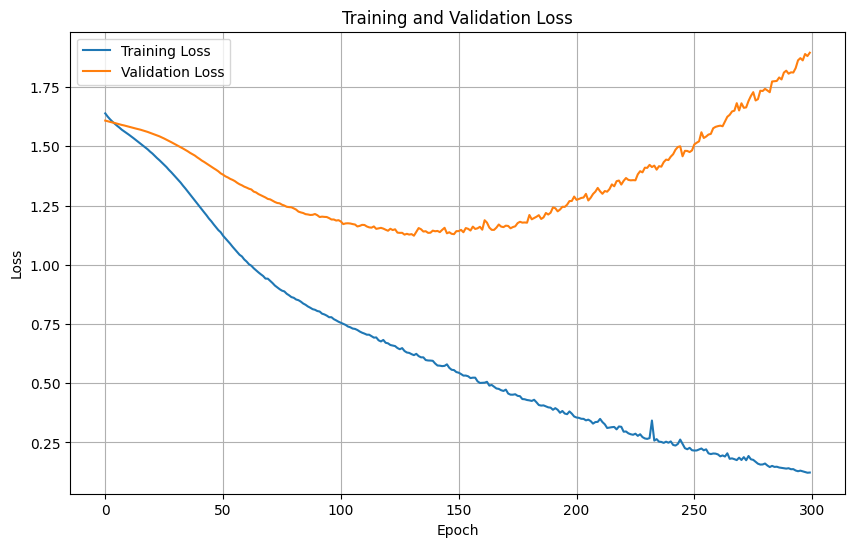

In [29]:
## Your code to plot training and validation curves in a single plot (Make changes in the model cell to be able to do this) :
plt.figure(figsize=(10, 6))
plt.plot(model_history.history['loss'], label='Training Loss')
plt.plot(model_history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

### Evaluate the Neural Network on the Test Set

In [30]:
#-- Generate predicted y values
pred_probabilities = keras_model.predict(preprocessor(X_test))
#Note: Keras predict returns class probabilities (one column per class).
#Use np.argmax(..., axis=1) to get the predicted column index for each row.
prediction_column_index= np.argmax(pred_probabilities, axis=1)

# extract correct prediction labels
prediction_labels = [y_train_oh.columns[i] for i in prediction_column_index]

## Write lines of code to show model performance by comparing prediction_labels with true labels:
print("Accuracy:", accuracy_score(y_test_labels, prediction_labels))
print(classification_report(
    y_test_labels,
    prediction_labels,
    labels=[0, 1, 2, 3, 4],
    target_names=["Very Low", "Low", "Average", "High", "Very High"],
    zero_division=0
))


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
Accuracy: 0.5476190476190477
              precision    recall  f1-score   support

    Very Low       0.50      0.67      0.57         9
         Low       0.33      0.25      0.29         8
     Average       0.57      0.50      0.53         8
        High       0.50      0.50      0.50         8
   Very High       0.78      0.78      0.78         9

    accuracy                           0.55        42
   macro avg       0.54      0.54      0.53        42
weighted avg       0.54      0.55      0.54        42



### Regularization: Dropout and Batch Normalization

Implement regularization techniques such as **Dropout** and **Batch Normalization** to improve generalization and observe the change in performance.

> **Note:** Compare training vs. test (or validation) loss and accuracy before and after adding regularization.

In [31]:
# Write your lines of code here:
from keras.layers import Dropout, BatchNormalization
from keras.callbacks import EarlyStopping

reg_model = Sequential()
reg_model.add(Dense(128))
reg_model.add(Activation('relu'))
reg_model.add(BatchNormalization())
reg_model.add(Dropout(0.3))

reg_model.add(Dense(128))
reg_model.add(Activation('relu'))
reg_model.add(BatchNormalization())
reg_model.add(Dropout(0.3))

reg_model.add(Dense(64))
reg_model.add(Activation('relu'))
reg_model.add(Dropout(0.2))

reg_model.add(Dense(64))
reg_model.add(Activation('relu'))
reg_model.add(Dropout(0.2))

reg_model.add(Dense(32))
reg_model.add(Activation('relu'))
reg_model.add(Dropout(0.2))

reg_model.add(Dense(5))
reg_model.add(Activation('softmax'))

reg_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
early_stopping=EarlyStopping(monitor="val_loss",patience=20,restore_best_weights=True)
reg_history = reg_model.fit(preprocessor(X_train), y_train_oh, batch_size=20, epochs=300, validation_split=0.25,callbacks=[early_stopping])


Epoch 1/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step - accuracy: 0.1549 - loss: 1.8650 - val_accuracy: 0.2083 - val_loss: 1.6207
Epoch 2/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1690 - loss: 1.8236 - val_accuracy: 0.2917 - val_loss: 1.6067
Epoch 3/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.3803 - loss: 1.5135 - val_accuracy: 0.2917 - val_loss: 1.5959
Epoch 4/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.3521 - loss: 1.6826 - val_accuracy: 0.2500 - val_loss: 1.5895
Epoch 5/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.3099 - loss: 1.4814 - val_accuracy: 0.2917 - val_loss: 1.5812
Epoch 6/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.3521 - loss: 1.4348 - val_accuracy: 0.2917 - val_loss: 1.5715
Epoch 7/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.4507 - loss: 1.3569 - val_accuracy: 0.3750 - val_loss: 1.5621
Epoch 8/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.3944 - loss: 1.3726 - val_accuracy: 0.3333 - val_loss

In [32]:
regularized_probabilities = reg_model.predict(preprocessor(X_test))
regularized_predictions = np.argmax(preprocessor(X_test), axis=1)

print("Regularized Model Test Accuracy:",
      accuracy_score(y_test_labels, regularized_predictions))

print("\nRegularized Model Classification Report:")
print(classification_report(
    y_test_labels,
    regularized_predictions,
    labels=[0, 1, 2, 3, 4],
    target_names=["Very Low", "Low", "Average", "High", "Very High"],
    zero_division=0
))

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 478ms/step
Regularized Model Test Accuracy: 0.0

Regularized Model Classification Report:
              precision    recall  f1-score   support

    Very Low       0.00      0.00      0.00       9.0
         Low       0.00      0.00      0.00       8.0
     Average       0.00      0.00      0.00       8.0
        High       0.00      0.00      0.00       8.0
   Very High       0.00      0.00      0.00       9.0

   micro avg       0.00      0.00      0.00      42.0
   macro avg       0.00      0.00      0.00      42.0
weighted avg       0.00      0.00      0.00      42.0



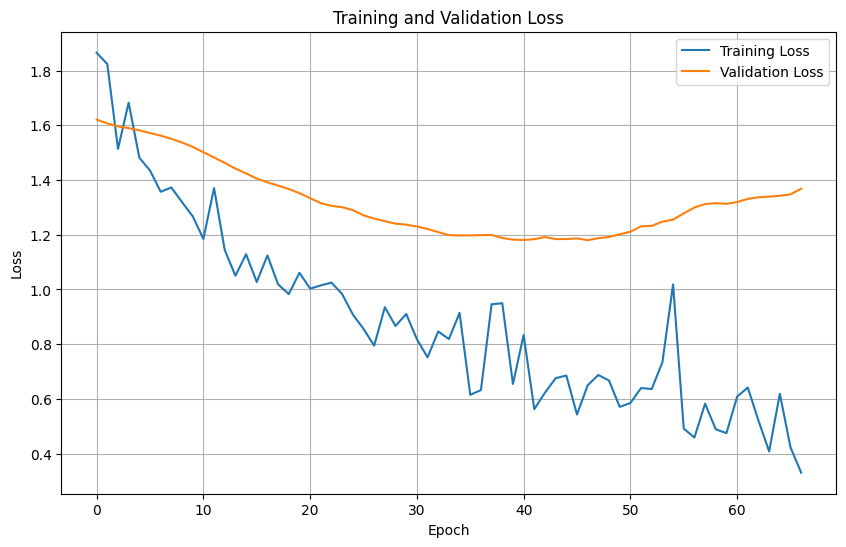

In [33]:
plt.figure(figsize=(10, 6))
plt.plot(reg_history.history['loss'], label='Training Loss')
plt.plot(reg_history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

*Replace this section with your response.*

**TODO**

### Activation Function Experimentation

Experiment with different activation functions — **ReLU**, **LeakyReLU**, **Tanh**, and **Sigmoid** — and compare their impact on model performance.

In [34]:
# Your lines of code here: TODO

---

## 8. Explainability – SHAP Feature Importance

To better understand the model's predictions, we will use **SHAP (SHapley Additive exPlanations)** to analyze feature importance.

**How SHAP works:**

- SHAP assigns each feature a contribution score for every prediction.
- It uses Shapley values (from cooperative game theory) to fairly distribute importance across features.

We will apply SHAP to visualize and interpret the model's feature contributions.

In [35]:
# Import necessary libraries
import shap
import matplotlib.pyplot as plt

# Transform the test data using the fitted preprocessor : TODO
# (SHAP needs the same numeric feature matrix the model was trained on, not raw X_test)

# Get feature names matching the columns after preprocessing : TODO
# (Hint: preprocess.get_feature_names_out())

# Initialize SHAP explainer: TODO
# Define an explainer that will help us interpret the model's decisions
# (Hint: Use shap.Explainer with your best-performing tree-based model, e.g., the best Random Forest from GridSearchCV.
#  Note that the variable `model` was reassigned in Section 6, so be explicit about which model you explain.)

explainer = ## Initialize SHAP explainer using the chosen trained model: TODO

# Compute SHAP values for the preprocessed test data
# This step generates Shapley values, which explain how each feature contributes to predictions
shap_values = ## Apply the explainer to the preprocessed X_test: TODO

# Generate SHAP summary plot
# This plot will show which features have the most impact on predictions
shap.summary_plot(## Pass the required parameters to create a summary plot: TODO)

# Your cell should output a SHAP summary plot showing the most important features.


SyntaxError: invalid syntax (2111970703.py, line 16)

### Explaining the Deep Learning Model

Deep learning models are often considered "black boxes" due to their complexity. Use SHAP to explain your model's predictions.

After applying SHAP, discuss:

- Does it provide a clear and sufficient explanation of how the model makes decisions?
- How easy or difficult is it to justify your model's predictions using this technique?

In [ ]:
## Your lines of Code and Answer: TODO

*Replace this section with your response.*

**TODO**

### Experimentation

In [ ]:
## You are encouraged to try more experimentation and any other models by adding more code cells to this notebook:

## You can also try to import any new dataset pertaining to countries, merge it, and see if it helps the predictions.
## If it does not, try to explain why it wasn't helpful by exploring variable relationships.

---

## 9. Final Summary

Summarize your project in a few short paragraphs. Include:

- A table comparing the test performance of every model you trained
- Your best-performing model, its hyperparameters, and why you think it performed best
- The most important insights from your EDA and SHAP analysis
- Limitations of your approach and what you would try next

*Replace this section with your response.*

**TODO**